In [1]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

from clustering.utils import SpaceTimeSVD

from tqdm import tqdm
import pygpcca

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [2]:
import tifffile

In [3]:
movie = tifffile.imread("/home/kushal/lab/datasets/jason/M19/D05/M19D5_MC.tif")[:10_000].astype(np.float32)

In [4]:
movie -= movie.mean(axis=0)

In [5]:
movie.shape

(10000, 512, 512)

In [6]:
%matplotlib inline

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
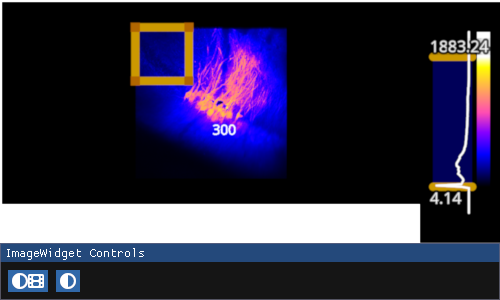

In [7]:
iw = fpl.ImageWidget(movie.std(axis=0), cmap="gnuplot2")
rs = iw.managed_graphics[0].add_rectangle_selector()
iw.show()

In [8]:
rs.selection = (162, 268, 178, 288)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
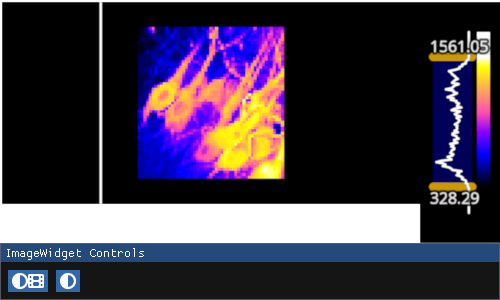

In [10]:
cols, rows = rs.get_selected_indices()
sub = movie[:, rows[0]:rows[-1]:2, cols[0]:cols[-1]:2]
iw_movie = fpl.ImageWidget(sub.std(axis=0), cmap="gnuplot2")
iw_movie.show()

In [11]:
sub.shape

(10000, 55, 53)

In [12]:
series = sub.reshape(sub.shape[0], sub.shape[1] * sub.shape[2]).T
series.shape

(2915, 10000)

In [14]:
stsvd = SpaceTimeSVD(series, w=8)

In [15]:
stsvd.compute(k=1)

Computing F, P


100%|█████████████████████████████████████████████████████████████████████████████████████| 2915/2915 [00:00<00:00, 5079.23it/s]


(2915, 10000)
(11660, 9992)


100%|████████████████████████████████████████████████████████████████████████████████████| 2915/2915 [00:00<00:00, 11471.98it/s]


computing H
Computing Hp
computimng svd of Hp


In [16]:
B = stsvd.adjacency

In [17]:
B = np.abs((B + B.T) / 2)

In [18]:
B

array([[3.03617790e-06, 2.09511713e-06, 1.47773392e-06, ...,
        2.46937656e-05, 1.95885066e-05, 1.84812026e-05],
       [2.09511713e-06, 2.39462354e-06, 8.69370619e-07, ...,
        1.45307561e-05, 9.70931906e-06, 1.35827168e-05],
       [1.47773392e-06, 8.69370619e-07, 3.58360641e-06, ...,
        1.35694072e-05, 1.99320009e-05, 1.58349848e-05],
       ...,
       [2.46937656e-05, 1.45307561e-05, 1.35694072e-05, ...,
        4.56807597e-03, 3.61243938e-03, 1.12784961e-03],
       [1.95885066e-05, 9.70931906e-06, 1.99320009e-05, ...,
        3.61243938e-03, 3.28281460e-03, 1.27517688e-03],
       [1.84812026e-05, 1.35827168e-05, 1.58349848e-05, ...,
        1.12784961e-03, 1.27517688e-03, 1.15427100e-03]])

In [19]:
B.shape

(2915, 2915)

In [20]:
d = 1 / np.sum(B, axis=0)

In [21]:
a = np.diag(d) @ B

In [22]:
import pygpcca as gp

In [23]:
gpcca = gp.GPCCA(a, z="LM", method="brandts")

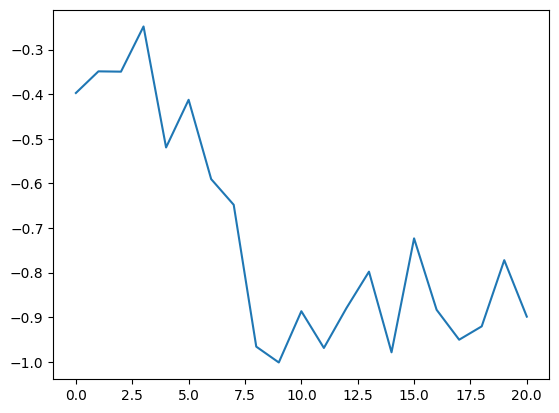

In [119]:
plt.plot(gpcca.minChi(10, 30))

In [24]:
%load_ext viztracer

In [120]:
# %%viztracer
gpcca.optimize({'m_min':13, 'm_max':14})

GPCCA[n=2915, n_macrostates=13]

In [121]:
gpcca.memberships.shape

(2915, 13)

In [122]:
gpcca.crispness_values

array([0.17894572, 0.14832259])

In [123]:
labels = gpcca.memberships.reshape(sub.shape[1], sub.shape[2], gpcca.memberships.shape[-1])

In [124]:
from ipywidgets import HBox

In [125]:
iw = fpl.ImageWidget([img.T for img in labels.T], names=[str(i) for i in range(labels.T.shape[0])], histogram_widget=False, figure_kwargs={"size": (1000, 1000)})
iw2 = fpl.ImageWidget(sub)
HBox([iw.show(), iw2.show()])

RFBOutputContext()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


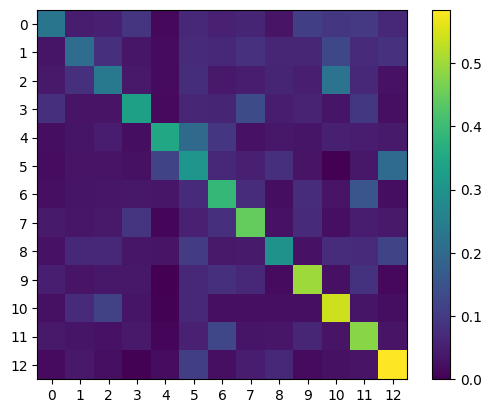

array([[ 2.27261563e-01,  4.46953064e-02,  5.07052057e-02,
         9.09223853e-02,  1.21184100e-02,  6.58308466e-02,
         5.43774298e-02,  6.03136980e-02,  2.96588900e-02,
         1.08931468e-01,  9.24664979e-02,  9.74965440e-02,
         6.52217557e-02],
       [ 3.36658819e-02,  2.08782426e-01,  8.03610764e-02,
         3.59884001e-02,  1.74448849e-02,  7.25952410e-02,
         6.42109313e-02,  8.35022196e-02,  6.31216141e-02,
         6.31230967e-02,  1.26191722e-01,  6.84848818e-02,
         8.25276248e-02],
       [ 3.96612921e-02,  7.93227082e-02,  2.36233188e-01,
         4.06633514e-02,  1.63519674e-02,  7.62305772e-02,
         3.92668050e-02,  4.48649873e-02,  5.97067708e-02,
         4.91624767e-02,  2.23042918e-01,  6.80309820e-02,
         2.74619752e-02],
       [ 7.99061379e-02,  3.12366448e-02,  3.14375497e-02,
         3.31668121e-01,  1.38268483e-02,  6.26797080e-02,
         6.11093877e-02,  1.34266525e-01,  4.41124331e-02,
         5.78418004e-02,  3.30141508e

In [126]:
P_c = gpcca.coarse_grained_transition_matrix
# plot P_c:
fig, ax = plt.subplots()
c = ax.imshow(P_c)
plt.xticks(np.arange(P_c.shape[1]))
plt.yticks(np.arange(P_c.shape[0]))
plt.ylim(-0.5, P_c.shape[0]-0.5)
ax.set_ylim(ax.get_ylim()[::-1])
fig.colorbar(c)
plt.show()
# show P_c matrix:
P_c

In [127]:
gpcca.coarse_grained_transition_matrix[gpcca.coarse_grained_transition_matrix < 0]

array([-0.00045199])

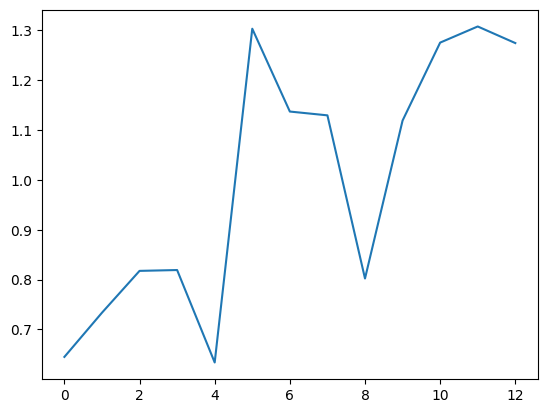

In [128]:
plt.plot(gpcca.coarse_grained_transition_matrix.sum(axis=0))